<a href="https://colab.research.google.com/github/KayraOrbay/GROUP37_CENG313/blob/eda-guncelleme/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CENG313 PROJECT

***Problem Definition***


This project is based on the competion in the Kaggle *Image Matching Challenge 2025*. Our main goal is to estimate 3D camera poses by identifying reliable matching points between 2D images of the same scene, which are captured from various viewpoints and lighting conditions.

Instead of a traditional tabular target, the dataset targets rotation matrices and translation vectors between images. These matrices will be calculated using matched keypoints.


The model's performance is measured using the mAA (Mean Average Accuracy) metric. This metric evaluates the accuracy of our predicted camera poses by calculating the rotation and translation errors compared to the ground truth.

In [46]:
print("Colab çalışıyor")

Colab çalışıyor


In [47]:
%pip install -q uv

In [48]:
!git clone https://github.com/KayraOrbay/GROUP37_CENG313.git

fatal: destination path 'GROUP37_CENG313' already exists and is not an empty directory.


In [49]:
%cd /content/GROUP37_CENG313
!ls

/content/GROUP37_CENG313
assignment1_eda_baseline.ipynb	GROUP37_CENG313  requirements.txt
data				README.md	 src


In [50]:
import subprocess
import sys
from pathlib import Path

requirements = Path("requirements.txt")
assert requirements.is_file(), "Repo klasöründe requirements.txt bulunamadı."

subprocess.run(
    [
        sys.executable, "-m", "uv", "pip", "install",
        "--system",
        "--python", sys.executable,
        "-r", str(requirements),
    ],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'uv', 'pip', 'install', '--system', '--python', '/usr/bin/python3', '-r', 'requirements.txt'], returncode=0)

In [51]:
# Proje yapisi ve kurulum kontrolu
from pathlib import Path
import sys

repo_root = Path('/content/GROUP37_CENG313')
assert (repo_root / 'src').is_dir(), 'src klasoru bulunamadi.'
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
import src
print('src import basarili')
print('src dosyalari:', [str(p.relative_to(repo_root)) for p in (repo_root / 'src').rglob('*') if p.is_file() and '__pycache__' not in str(p)])
for name in ['README.md', 'requirements.txt', '.gitignore']:
    p = repo_root / name
    print('\n---', name, '---')
    print(p.read_text()[:12000] if p.exists() else 'Dosya yok')

src import basarili
src dosyalari: ['src/data.py', 'src/_init_.py', 'src/evaluation.py', 'src/models.py']

--- README.md ---
# image-matching-challenge-2025
"https://www.kaggle.com/competitions/image-matching-challenge-2025"

Ayşegül Pınar Yılmaz 
23118080004
Cherrylin

Kayra Orbay
23118080017 
KayraOrbay


--- requirements.txt ---


--- .gitignore ---
# Datasets and downloaded archives
data/
datasets/
train_labels.csv
train_thresholds.csv
sample_submission.csv
*.zip

# Model weights
weights/
checkpoints/
*.pt
*.pth
*.ckpt
*.h5
*.onnx
*.safetensors

# Credentials
.env
.env.*
!.env.example
secrets/
kaggle.json
credentials.json
service-account*.json
*.pem
*.key

# Python and notebook temporary files
.venv/
__pycache__/
*.pyc
.ipynb_checkpoints/



In [52]:
# Gercek proje modullerini kontrol et
import importlib
for module_name in ['src.data', 'src.models', 'src.evaluation']:
    module = importlib.import_module(module_name)
    print(module_name, 'OK:', module.__file__)
    print(Path(module.__file__).read_text()[:8000] or '(Dosya bos)')

# Veri, model agirliklari ve erisim bilgilerini Git takibinden haric tut
ignore_path = repo_root / '.gitignore'
existing = ignore_path.read_text() if ignore_path.exists() else ''
rules = ['data/', 'datasets/', 'weights/', 'checkpoints/', '*.pt', '*.pth', '*.ckpt', '*.h5', '*.onnx', '*.safetensors', '*.zip', '.env', '.env.*', '!.env.example', 'secrets/', 'kaggle.json', 'credentials.json', 'service-account*.json', '*.pem', '*.key', '__pycache__/', '*.pyc', '.ipynb_checkpoints/']
missing = [rule for rule in rules if rule not in existing.splitlines()]
if missing:
    ignore_path.write_text(existing + ('\n' if existing and not existing.endswith('\n') else '') + '\n'.join(missing) + '\n')
print('\n.gitignore hazir:', ignore_path)
print('Veri klasorleri:', [str(p) for p in [repo_root / 'data', Path('/content/data'), Path('/content/drive/MyDrive')] if p.exists()])

src.data OK: /content/GROUP37_CENG313/src/data.py
from pathlib import Path
import numpy as np
import pandas as pd

REQUIRED_COLUMNS = ["dataset", "scene", "image", "rotation_matrix", "translation_vector"]

def load_train_labels(data_dir="data"):
    df = pd.read_csv(Path(data_dir) / "train_labels.csv")
    missing = set(REQUIRED_COLUMNS) - set(df.columns)
    if missing:
        raise ValueError(f"train_labels.csv is missing columns: {missing}")
    return df

def load_train_thresholds(data_dir="data"):
    return pd.read_csv(Path(data_dir) / "train_thresholds.csv")

def load_sample_submission(data_dir="data"):
    return pd.read_csv(Path(data_dir) / "sample_submission.csv")

def _parse_vector(value, expected_len):
    if pd.isna(value):
        return np.full(expected_len, np.nan)
    parts = [p for p in str(value).split(";") if p != ""]
    arr = np.array([float(p) for p in parts], dtype=float)
    if arr.size != expected_len:
        raise ValueError(f"Expected {expected_len} values

In [53]:
# Kaggle train_labels.csv dosyasini oku; ek paket gerektirmez.
from pathlib import Path
import importlib
import sys
from google.colab import files

repo_root = Path('/content/GROUP37_CENG313')
assert (repo_root / 'src').is_dir(), 'Once repo klonlama ve kurulum hucrelerini calistirin.'
loader_source = '''import csv
from pathlib import Path

def read_train_labels(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.DictReader(handle)
        required = {"dataset", "scene", "image", "rotation_matrix", "translation_vector"}
        if not required.issubset(reader.fieldnames or []):
            raise ValueError("Beklenen train_labels.csv sutunlari eksik.")
        rows = list(reader)
    if not rows:
        raise ValueError("Etiket dosyasi bos.")
    return rows
'''
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
import src.data
importlib.reload(src.data)

data_dir = repo_root / 'data'
data_dir.mkdir(exist_ok=True)
labels_path = data_dir / 'train_labels.csv'
if not labels_path.exists():
    print('Kaggle sitesinden indirilen train_labels.csv dosyasini secin.')
    uploaded = files.upload()
    if 'train_labels.csv' not in uploaded:
        raise ValueError('train_labels.csv secilmedi.')
    labels_path.write_bytes(uploaded['train_labels.csv'])

rows = src.data.read_train_labels(labels_path)
print('Veri okuma basarili. Satir sayisi:', len(rows))
print('Sutunlar:', list(rows[0]))
print('Ilk kayit:', rows[0])
print('Veri kumesi sayisi:', len({row['dataset'] for row in rows}))

Veri okuma basarili. Satir sayisi: 1945
Sutunlar: ['dataset', 'scene', 'image', 'rotation_matrix', 'translation_vector']
Ilk kayit: {'dataset': 'imc2023_haiper', 'scene': 'fountain', 'image': 'fountain_image_116.png', 'rotation_matrix': '0.122655949;0.947713775;-0.294608417;0.122670643;0.280096125;0.952101924;0.984838784;-0.152920769;-0.081901202', 'translation_vector': '0.093771314;-0.803560988;2.062001533'}
Veri kumesi sayisi: 13


In [54]:
%%writefile /content/GROUP37_CENG313/src/data.py
from pathlib import Path
import numpy as np
import pandas as pd

REQUIRED_COLUMNS = ["dataset", "scene", "image", "rotation_matrix", "translation_vector"]

def load_train_labels(data_dir="data"):
    df = pd.read_csv(Path(data_dir) / "train_labels.csv")
    missing = set(REQUIRED_COLUMNS) - set(df.columns)
    if missing:
        raise ValueError(f"train_labels.csv is missing columns: {missing}")
    return df

def load_train_thresholds(data_dir="data"):
    return pd.read_csv(Path(data_dir) / "train_thresholds.csv")

def load_sample_submission(data_dir="data"):
    return pd.read_csv(Path(data_dir) / "sample_submission.csv")

def _parse_vector(value, expected_len):
    if pd.isna(value):
        return np.full(expected_len, np.nan)
    parts = [p for p in str(value).split(";") if p != ""]
    arr = np.array([float(p) for p in parts], dtype=float)
    if arr.size != expected_len:
        raise ValueError(f"Expected {expected_len} values, got {arr.size}: {value!r}")
    return arr

def parse_poses(df):
    out = df.copy()
    R = np.vstack(out["rotation_matrix"].apply(_parse_vector, expected_len=9).to_numpy())
    t = np.vstack(out["translation_vector"].apply(_parse_vector, expected_len=3).to_numpy())
    out[[f"R{i}{j}" for i in range(3) for j in range(3)]] = R
    out[["tx", "ty", "tz"]] = t
    return out

Overwriting /content/GROUP37_CENG313/src/data.py


In [55]:
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 40)

# Data Shape
display(Markdown("### 1. Data shape"))
shape_table = pd.DataFrame(
    {"rows": [df.shape[0] for df in (labels, thresholds, sample_sub)],
     "columns": [df.shape[1] for df in (labels, thresholds, sample_sub)]},
    index=["train_labels", "train_thresholds", "sample_submission"])
display(shape_table)

# Datasets / Scenes
display(Markdown("### 2. Datasets and scenes"))
print("Unique datasets:", labels["dataset"].nunique())
print("Unique (dataset, scene) pairs:", labels.groupby(["dataset", "scene"]).ngroups)

# Data Types
display(Markdown("### 3. Data types (train_labels)"))
types_table = pd.DataFrame({
    "dtype": labels.dtypes.astype(str),
    "non_null": labels.notna().sum(),
    "unique": labels.nunique(),
    "example": labels.iloc[0].astype(str).str.slice(0, 40),
})
display(types_table)

# Missing values
display(Markdown("### 4. Missing values"))
# Missing poses can be real NaN cells or text like "nan;nan;nan"
empty_cells = labels.isna()
nan_text = labels.apply(lambda col: col.astype(str).str.fullmatch(r"(?i)nan(;nan)*")) & ~empty_cells
missing_table = pd.DataFrame({
    "empty (NaN)": empty_cells.sum(),
    "'nan;nan;...' text": nan_text.sum(),
    "total missing": (empty_cells | nan_text).sum(),
    "missing_%": ((empty_cells | nan_text).mean() * 100).round(2),
})
display(missing_table)

# Duplicates
display(Markdown("### 5. Duplicates"))
duplicate_table = pd.DataFrame({"count": [
    labels.duplicated().sum(),
    labels.duplicated(["dataset", "image"]).sum(),
    labels["image"].duplicated().sum(),
]}, index=["fully duplicated rows",
           "duplicated (dataset, image)",
           "same image name in another dataset"])
display(duplicate_table)

# describe()
display(Markdown("### 6. Summary statistics – describe()"))
summary = labels.describe(include="all").T
summary["top"] = summary["top"].astype(str).str.slice(0, 40)
display(summary)


### 1. Data shape

,rows,columns
train_labels,1945,5
train_thresholds,30,3
sample_submission,1945,6


### 2. Datasets and scenes

Unique datasets: 13
Unique (dataset, scene) pairs: 34


### 3. Data types (train_labels)

,dtype,non_null,unique,example
dataset,object,1945,13,imc2023_haiper
scene,object,1945,30,fountain
image,object,1945,1937,fountain_image_116.png
rotation_matrix,object,1945,1824,0.122655949;0.947713775;-0.294608417...
translation_vector,object,1945,1824,0.093771314;-0.803560988;2.062001533


... (2 outputs left out)

### 5. Duplicates

,count
fully duplicated rows,0
"duplicated (dataset, image)",0
same image name in another dataset,8


### 6. Summary statistics – describe()

,count,unique,top,freq
dataset,1945,13,pt_brandenburg_british_buckingham,225
scene,1945,30,peach,200
image,1945,1937,dioscuri_archive_0026.png,2
rotation_matrix,1945,1824,nan;nan;nan;nan;nan;nan;nan;nan;nan,122
translation_vector,1945,1824,nan;nan;nan,122


***Data Overview***

1. Data shape

In the results of the previous code, we see that train_labels.csv has 1945 rows and 5 columns, so we have 1945 training images in total. sample_submission.csv also has 1945 rows which shows us that the submission file covers the same images, just in a different format. train_thresholds.csv has 30 rows and when we look at it we can say that each row belongs to one scene.

2. Datasets and scenes

We see that the images come from 13 datasets and [X] (dataset, scene) pairs. Looking at these, we can say that one dataset can include more than one scene. For example, pt_brandenburg_british_buckingham has 3 different scenes. This tells us that the task is not only estimating camera poses; we also need to figure out which images belong to the same scene.

3. Data types

In this table we see that all columns are object which means they are stored as text. This is expected for dataset, scene and image but we notice that rotation_matrix and translation_vector are also text. When we look at the example values, we see that they are numbers separated by ; (9 values for rotation, 3 for translation). So we can say that before doing any numerical analysis we first need to convert these strings into numeric arrays.

4. Missing values

Here we see that dataset, scene and image have no missing values. However, rotation_matrix and translation_vector are missing in [122] rows. When we checked which rows these are we noticed that all of them belong to the outliers scene. From this we can say that these are not really "missing data". These images do not belong to any scene, so they have no camera pose on purpose. Since finding these outlier images is also part of the challenge, we will leave them out only when we calculate pose statistics.

5. Duplicates

In this table we see that there are no fully duplicated rows and no duplicated (dataset, image) pairs, so every image appears only once inside its dataset. However, when we look only at the image names, we see that [8] image names appear in two different datasets. When we checked these rows, we noticed that they come from the dioscuri scene, which is included both in imc2023_heritage and imc2024_dioscuri_baalshamin. Because of this, we can say that the image name alone is not enough to identify an image, so we will use the (dataset, image) pair as a unique key.

6. Summary statistics

From the describe() results we see that every value in the image column is unique, which matches what we found in the duplicates part. On the other hand, dataset and scene are not evenly distributed. The most frequent dataset is [top dataset] with [freq] images and the most frequent scene is [top scene] with [freq] images. Looking at this, we can say that some scenes have many more images than others, so we need to look at this imbalance in more detail in the EDA part. We also see that the most frequent value in the rotation_matrix and translation_vector columns is the nan pattern, which again points to the outlier images we found in the missing values part.

**Exploratory Data Analysis (EDA)**

In this part we explore the camera poses (our target) and how the images are distributed over datasets and scenes. Before the analysis, we parsed rotation_matrix and translation_vector into numbers and calculated some extra values from them, like the rotation angle and the camera position (C = -R^T t). We should note that every scene has its own coordinate system, so the absolute values of different scenes cannot be compared directly.

In [56]:
%%writefile -a /content/GROUP37_CENG313/src/data.py


def add_pose_features(df):
    """Parse poses and add simple numeric features for EDA.

    rot_angle_deg : rotation angle of R (0 = same orientation as the reference)
    t_norm        : length of the translation vector
    cx, cy, cz    : camera center in world coordinates, C = -R^T t
    dist_to_center: distance of the camera to the median camera center of its scene
    det_R, orth_err: sanity checks (a valid rotation has det = 1 and R R^T = I)
    """
    out = parse_poses(df)
    r_cols = [f"R{i}{j}" for i in range(3) for j in range(3)]
    R = out[r_cols].to_numpy().reshape(-1, 3, 3)
    t = out[["tx", "ty", "tz"]].to_numpy()

    trace = np.trace(R, axis1=1, axis2=2)
    out["rot_angle_deg"] = np.degrees(np.arccos(np.clip((trace - 1) / 2, -1, 1)))
    out["t_norm"] = np.linalg.norm(t, axis=1)
    C = -np.einsum("nji,nj->ni", R, t)
    out[["cx", "cy", "cz"]] = C
    with np.errstate(invalid="ignore"):  # outlier rows are NaN
        out["det_R"] = np.linalg.det(R)
        out["orth_err"] = np.linalg.norm(R @ R.transpose(0, 2, 1) - np.eye(3), axis=(1, 2))

    centers = out.groupby(["dataset", "scene"])[["cx", "cy", "cz"]].transform("median")
    out["dist_to_center"] = np.linalg.norm(out[["cx", "cy", "cz"]].to_numpy() - centers.to_numpy(), axis=1)
    out["is_outlier_image"] = out["scene"].eq("outliers") | out["tx"].isna()
    return out

Appending to /content/GROUP37_CENG313/src/data.py


In [57]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import src.data
importlib.reload(src.data)
from src.data import add_pose_features

sns.set_theme(style="whitegrid")
df = add_pose_features(labels)
poses_ok = df[~df["is_outlier_image"]].copy()
print("All images:", len(df), "| with pose:", len(poses_ok), "| outlier images:", df["is_outlier_image"].sum())

All images: 1945 | with pose: 1823 | outlier images: 122


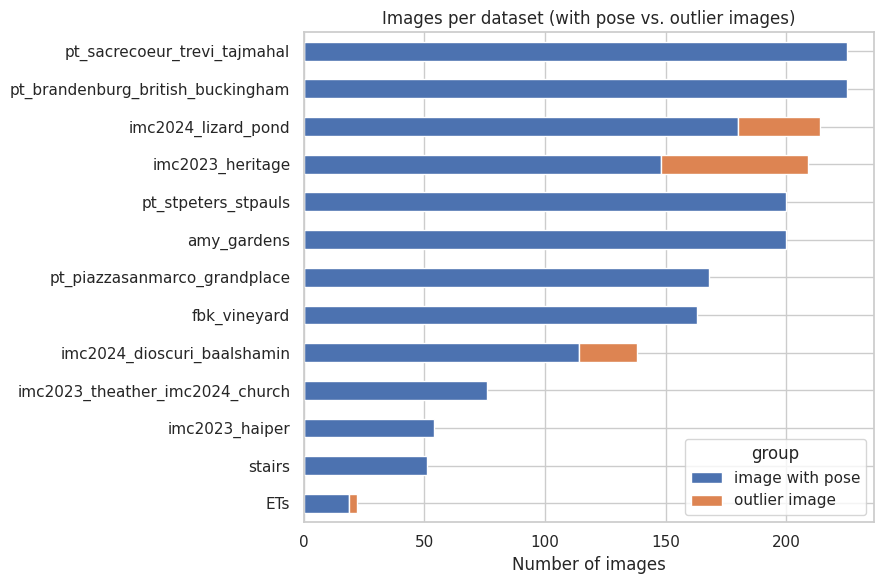

In [58]:
counts = (df.assign(group=np.where(df["is_outlier_image"], "outlier image", "image with pose"))
            .groupby(["dataset", "group"]).size().unstack(fill_value=0))
counts = counts.loc[counts.sum(axis=1).sort_values().index]
ax = counts.plot(kind="barh", stacked=True, figsize=(9, 6), color=["#4C72B0", "#DD8452"][:counts.shape[1]])
ax.set_xlabel("Number of images"); ax.set_ylabel("")
ax.set_title("Images per dataset (with pose vs. outlier images)")
plt.tight_layout(); plt.show()

1. Images per dataset (target balance)

In this plot we see that the number of images is quite different between datasets. The biggest datasets like pt_sacrecoeur_trevi_tajmahal and pt_brandenburg_british_buckingham have 225 images, while ETs has only 22 images. We also notice that outlier images (orange) appear in only 4 datasets: imc2024_lizard_pond, imc2023_heritage, imc2024_dioscuri_baalshamin and ETs. imc2023_heritage has the largest share of outliers, with 61 of its 209 images (29.2%), which means almost one third of its images do not belong to any scene. Looking at this, we can say that our model should not assume every image belongs to a scene, because in some datasets a big part of the images are outliers that we need to reject.

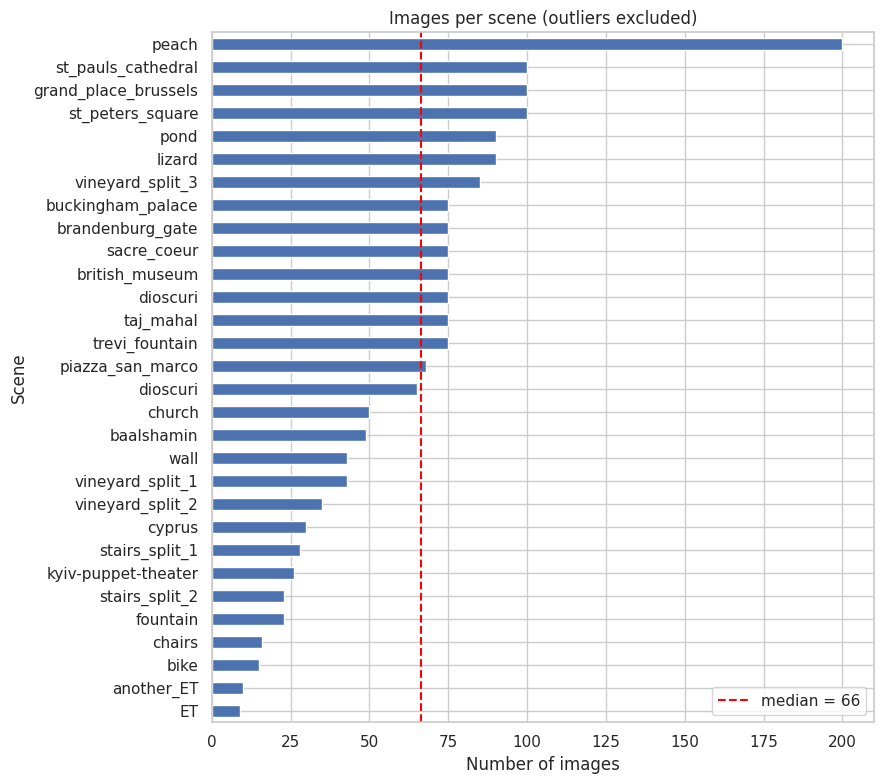

count     30.0
mean      60.8
std       39.3
min        9.0
25%       28.5
50%       66.5
75%       75.0
max      200.0
dtype: float64


In [59]:
scene_counts = poses_ok.groupby(["dataset", "scene"]).size().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
scene_counts.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_yticklabels([s for _, s in scene_counts.index])
ax.axvline(scene_counts.median(), color="red", ls="--", label=f"median = {scene_counts.median():.0f}")
ax.set_xlabel("Number of images"); ax.set_ylabel("Scene"); ax.legend()
ax.set_title("Images per scene (outliers excluded)")
plt.tight_layout(); plt.show()
print(scene_counts.describe().round(1))

2. Images per scene (target balance)

Here we see that there are 30 scenes and the median number of images per scene is 66. The scenes are not balanced: peach has 200 images, which is much more than the others, while ET and another_ET have only 9 and 10 images. All of the phototourism scenes (st_pauls_cathedral, grand_place_brussels, st_peters_square etc.) are above the median, while the imc2023_haiper scenes (fountain, chairs, bike) and ETs are at the bottom. We also see dioscuri twice because the same scene exists in two different datasets. From this we can say that small scenes will be harder to reconstruct since there are fewer images to match. Also, since mAA is calculated separately for each scene, every single image in a small scene has a bigger effect on that scene's score than an image in a big scene.

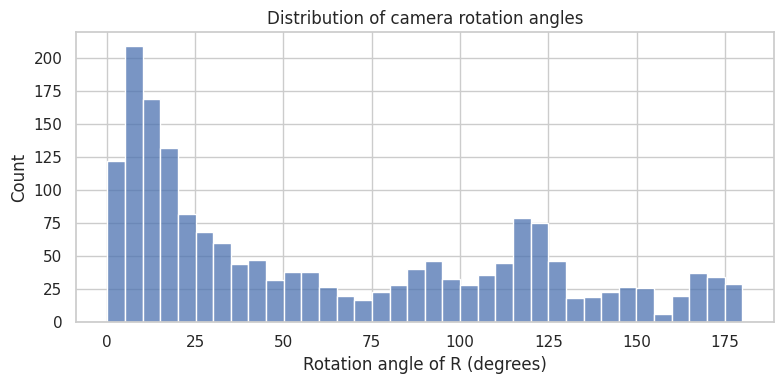

In [60]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(poses_ok["rot_angle_deg"], bins=36, ax=ax)
ax.set_xlabel("Rotation angle of R (degrees)"); ax.set_title("Distribution of camera rotation angles")
plt.tight_layout(); plt.show()

3. Distribution of camera rotation angles (distribution)

In this histogram we see that the highest bar is between about 5 and 10 degrees, and around 40% of the cameras have a rotation angle below 25 degrees. This means a large group of cameras have an orientation close to the reference coordinate system of their scene. However, the distribution has a long tail and a second peak around 115-125 degrees, and some cameras go up to 180 degrees. Looking at this, we can say that the data includes photos taken from very different, even opposite, viewing directions. Matching keypoints between these images will be harder, so our method needs features that are robust to large viewpoint changes.

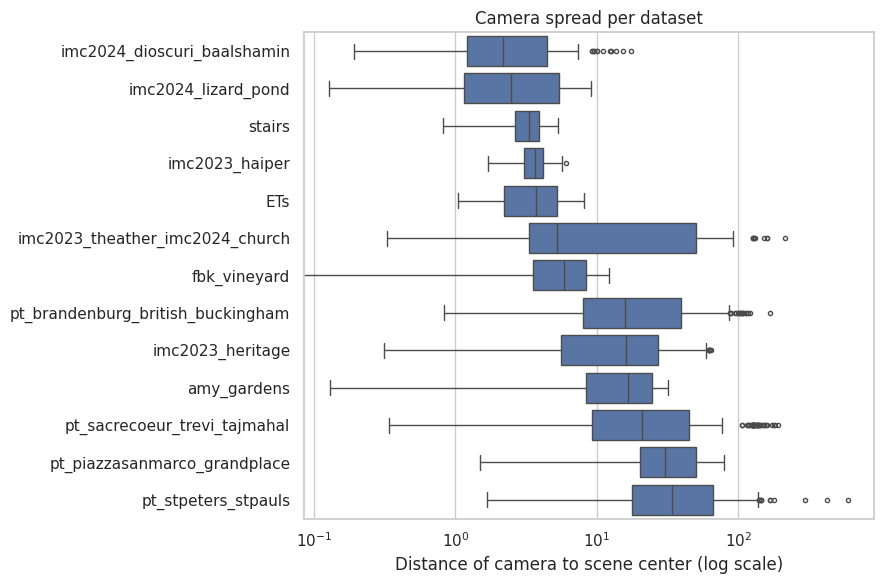

In [61]:
order = poses_ok.groupby("dataset")["dist_to_center"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=poses_ok, y="dataset", x="dist_to_center", order=order, ax=ax, color="#4C72B0", fliersize=3)
ax.set_xscale("log")
ax.set_xlabel("Distance of camera to scene center (log scale)"); ax.set_ylabel("")
ax.set_title("Camera spread per dataset")
plt.tight_layout(); plt.show()

4. Camera spread per dataset (distribution and outliers)

In this boxplot we see how far the cameras are from the center of their scene (in log scale). The values change a lot between datasets: in imc2024_dioscuri_baalshamin, imc2024_lizard_pond, stairs, imc2023_haiper and ETs the median distance is only between 2.2 and 3.7 units, while in the phototourism datasets (pt_...) the median is between 15.8 and 34.1 units and some cameras go above 100. imc2023_theather_imc2024_church has a very wide box, which we think is because its two scenes have very different scales. We also notice that many of the outlier points (small circles) are in the phototourism datasets. From this we can say that the scale of each dataset is very different, and this is probably why the competition uses different thresholds for each dataset in train_thresholds.csv. The outlier points in phototourism probably come from tourist photos taken from much further away than the others.

In [63]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

poses_ok["far_camera"] = poses_ok.groupby(["dataset", "scene"])["dist_to_center"].transform(iqr_flags)
outlier_summary = (poses_ok.groupby(["dataset", "scene"])
                   .agg(images=("image", "size"), far_cameras=("far_camera", "sum"))
                   .assign(far_pct=lambda d: (100 * d["far_cameras"] / d["images"]).round(1))
                   .sort_values("far_pct", ascending=False))
display(outlier_summary.head(10))
print("Total far cameras (IQR rule):", int(poses_ok["far_camera"].sum()), "of", len(poses_ok))
print("Rotation check -> det(R) range:", round(poses_ok["det_R"].min(), 4), "to", round(poses_ok["det_R"].max(), 4),
      "| max orthogonality error:", round(poses_ok["orth_err"].max(), 6))

,,images,far_cameras,far_pct
dataset,scene,,,
imc2023_haiper,fountain,23,4,17.4
pt_sacrecoeur_trevi_tajmahal,sacre_coeur,75,8,10.7
imc2024_dioscuri_baalshamin,baalshamin,49,5,10.2
ETs,another_ET,10,1,10.0
pt_stpeters_stpauls,st_pauls_cathedral,100,9,9.0
pt_piazzasanmarco_grandplace,piazza_san_marco,68,6,8.8
pt_brandenburg_british_buckingham,brandenburg_gate,75,6,8.0
imc2024_dioscuri_baalshamin,dioscuri,65,5,7.7
imc2023_haiper,chairs,16,1,6.2


Total far cameras (IQR rule): 49 of 1823
Rotation check -> det(R) range: 1.0 to 1.0 | max orthogonality error: 6e-06


5. Outlier cameras (outliers)

To find unusual cameras, we used the IQR rule on the distance to the scene center, separately for each scene. In the table we see that only 49 of 1823 cameras (around 2.7%) are flagged as far cameras. The highest share is in fountain (4 of 23 cameras, 17.4%), followed by sacre_coeur and baalshamin with around 10%. We also checked if all rotation matrices are valid (det(R) = 1 and R R^T = I), and we see that det(R) is 1.0 for every camera and the largest orthogonality error is only 6e-06, so all rotation matrices are valid. Looking at this, we can say that these far cameras are not data errors but real photos taken from a bigger distance. That is why we decided to keep them, but we expect these images to be harder to register because they share fewer keypoints with the others.

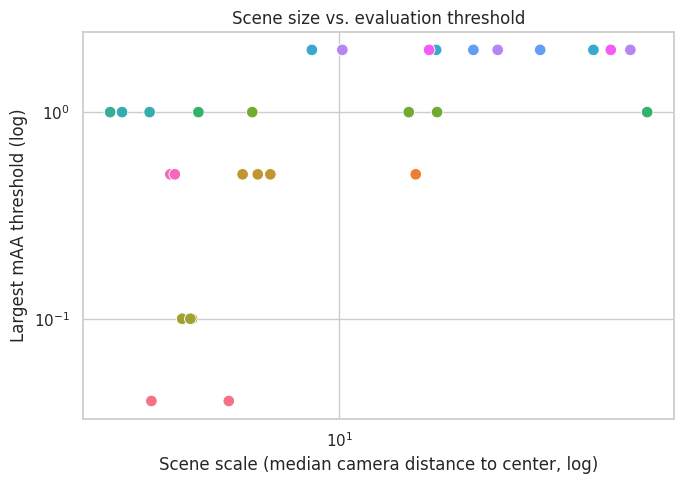

Spearman correlation: 0.62


In [64]:
thr = thresholds.copy()
thr_vals = thr["thresholds"].str.split(";").apply(lambda v: [float(x) for x in v])
thr["thr_max"] = thr_vals.apply(max)
scale = poses_ok.groupby(["dataset", "scene"])["dist_to_center"].median().rename("scene_scale").reset_index()
rel = scale.merge(thr, on=["dataset", "scene"], how="inner")
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=rel, x="scene_scale", y="thr_max", hue="dataset", s=70, ax=ax, legend=False)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Scene scale (median camera distance to center, log)")
ax.set_ylabel("Largest mAA threshold (log)")
ax.set_title("Scene size vs. evaluation threshold")
plt.tight_layout(); plt.show()
print("Spearman correlation:", rel["scene_scale"].corr(rel["thr_max"], method="spearman").round(2))

6. Scene size vs. evaluation threshold (relationship with the target)

In this plot we compare the size of each scene (median camera distance to the center) with the largest mAA threshold of that scene. We see a positive relationship, and the Spearman correlation is 0.62. Most of the scenes with a scale above 10 (mostly phototourism scenes) have the largest threshold of 2.0, while the smallest scenes have much smaller thresholds like 0.1 or 0.04. We also notice that points with the same color, which belong to the same dataset, are on the same horizontal line, so the thresholds are chosen per dataset and not per scene. Looking at this, we can say that the competition uses bigger thresholds for bigger scenes. This means the same pose error (for example 1 unit) is a small mistake in a big scene but a big mistake in a small scene. Because of this, we should not compare raw pose errors between scenes and should always evaluate them with their own thresholds.

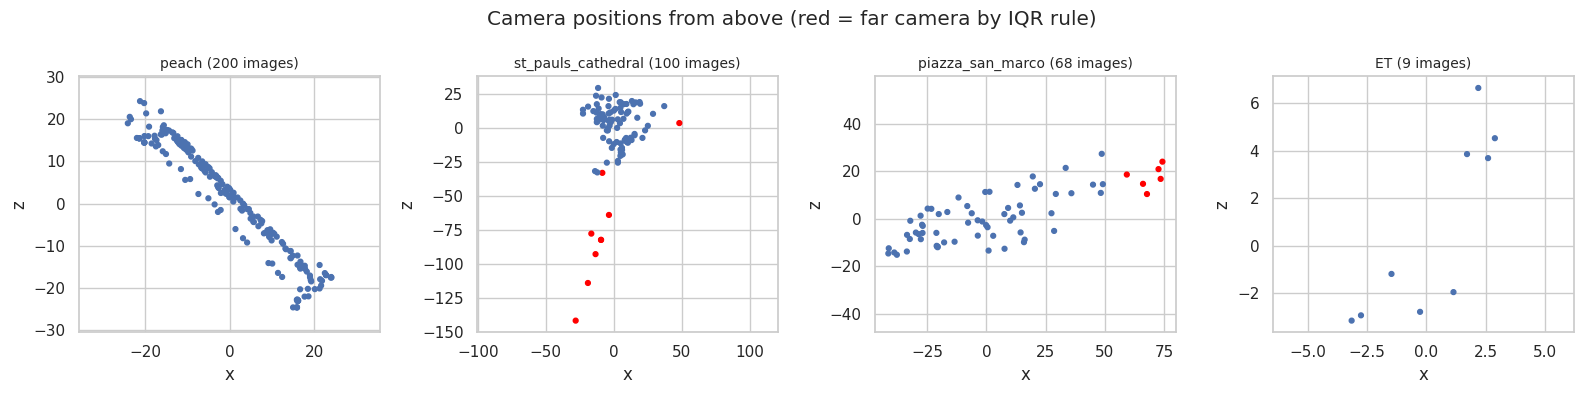

In [65]:
examples = scene_counts.index[[-1, -2, len(scene_counts) // 2, 0]]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (ds, sc) in zip(axes, examples):
    s = poses_ok[(poses_ok["dataset"] == ds) & (poses_ok["scene"] == sc)]
    ax.scatter(s["cx"], s["cz"], s=12, c=s["far_camera"].map({True: "red", False: "#4C72B0"}))
    ax.set_title(f"{sc} ({len(s)} images)", fontsize=10); ax.set_xlabel("x"); ax.set_ylabel("z")
    ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("Camera positions from above (red = far camera by IQR rule)")
plt.tight_layout(); plt.show()

7. Camera positions in example scenes (relationship with the target)

Here we see the camera positions from above for four scenes with different sizes. In peach (200 images) the cameras are placed almost on a straight line, which looks like the photographer walked along a path while taking photos. In st_pauls_cathedral most cameras are close together around the center, but the red far cameras go down to around -140 on the z axis, so some photos were taken from much further away. In piazza_san_marco the cameras are spread over a wide area and the far cameras are all on the right side of the square. ET has only 9 cameras that are far from each other, so there are big gaps between the viewpoints. From this we can say that every scene has a different camera layout: scenes like peach, where neighboring images are very close to each other, should be easier to match, while scenes with few and widely spread cameras like ET will be harder for our model.